# 03 - Preparação dos Dados para Classificação

Este notebook segue a mesma lógica do `01_preparação_clustering.ipynb`, mas prepara os dados para os **algoritmos de classificação** da classe `Classifier` (`src/classifier.py`).

**Diferenças em relação à preparação para clustering:**
- Na classificação o target (`cancer_recurrence`) é usado **para treinar** o modelo (aprendizado supervisionado), e não apenas para avaliar.
- A classe `Classifier` espera um DataFrame com as features e uma coluna alvo chamada **`classe`**.
- **Não** escalonamos os dados aqui: o `Pipeline` do `Classifier` já aplica `StandardScaler` / `OneHotEncoder` **dentro** da validação cruzada, o que evita vazamento de informação (*data leakage*) entre os folds.

**Etapas:**
1. Carregar e limpar os dados (mesmo processamento do 00/01)
2. Escolher a representação dos genótipos (dummies, grupos ou frequências)
3. Montar o DataFrame no formato esperado pelo `Classifier` (features + `classe`)
4. Dividir em treino (60%), validação (20%) e teste (20%) de forma estratificada
5. Salvar os dados com `joblib`

## 1. Importações

In [ ]:
import os

try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

# Manipulação de dados
import pandas as pd
import numpy as np

# Persistência dos objetos (salvar/carregar)
from joblib import dump, load

# Divisão dos dados em treino / validação / teste
from sklearn.model_selection import train_test_split

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

os.listdir("./")

['db',
 '04a_classificação.md',
 '04_classificação.ipynb',
 'data_report.html',
 '06_regressão.ipynb',
 '00_analítica.ipynb',
 'data',
 'src',
 '05_preparação_regressão.ipynb',
 '03_preparação_classificação.ipynb',
 '01_preparação_clustering.ipynb',
 'pergunta.txt',
 '02_clustering.ipynb']

## 2. Carregar e Processar os Dados

Replicamos exatamente o processamento do `01_preparação_clustering.ipynb` para garantir que clustering e classificação partam da **mesma base**.

In [ ]:
# -- LEITURA DO BANCO DE DADOS --
# As 6 primeiras linhas da planilha são cabeçalhos/legendas e são ignoradas
df_followup = pd.read_excel("db/Follow_Up_Dissertação.xlsx", skiprows=[0, 1, 2, 3, 4, 5])

print(f"Shape original: {df_followup.shape}")

Shape original: (221, 55)


In [ ]:
# -- RENOMEAR COLUNAS E REMOVER COLUNAS DESNECESSÁRIAS --
# Cada gene aparece em 3 colunas (codificação original + 2 agrupamentos).
# Mantemos apenas a codificação original (1, 2, 3) e damos o nome do gene.
df_followup = df_followup.rename(columns={"Código": "id",
                                          "Unnamed: 1": "GSTP1",
                                          "Unnamed: 4": "MGMT",
                                          "Unnamed: 7": "VDR",
                                          " (AA=1 CA=2 CC=3) ": "BCL2",
                                          "AA= 1 GA=2 GG=3": "CASP9",
                                          "CC=1 TC=2 TT=3": "NKX3",
                                          "TT=1 CT=2 CC=3": "CASP3",
                                          "GG=1 CG=2 CC=3": "PTEN",
                                          "GG=1 CG=2 CC=3.1": "AKT1",
                                          "AA=1 GA=2 GG=3": "PI3K",
                                          "AA=1 GA=2 GG=3.1": "AMACR",
                                          "AA=1 GG=2": "AR",
                                          "CC=1 CT=2 TT=3": "MTOR",
                                          "Recidiva": "cancer_recurrence"})

# Remove as colunas de agrupamentos alternativos dos genótipos
df_followup = df_followup.drop(df_followup.columns[[2, 3, 5, 6, 8, 9, 11, 12, 14, 15, 17, 18, 20, 21, 23, 24, 26, 27, 29, 30, 32, 33, 36, 37]], axis=1)

print(f"Colunas após renomear: {list(df_followup.columns)}")

Colunas após renomear: ['id', 'GSTP1', 'MGMT', 'VDR', 'BCL2', 'CASP9', 'NKX3', 'CASP3', 'PTEN', 'AKT1', 'PI3K', 'AMACR', 'AR', 'MTOR', 'Hormonioterapia N=0 S=1', 'MEDICAMENTO3', 'Data inicial', 'Radioterapia', 'Data inicial2', 'Data final3', 'MEDICAMENTO2', 'Metástase óssea ', 'Orquei', 'cancer_recurrence', 'CPRC', 'novo tumor', 'orgão', 'óbito', 'data Obito', 'motivo do obito', 'Unnamed: 54']


In [4]:
# -- SUBSTITUIR VALORES INT POR STR (GENÓTIPOS) --
# Os genótipos estão codificados como 1, 2, 3. Convertê-los em texto deixa
# claro que são variáveis CATEGÓRICAS (e não numéricas/ordinais).
gene_dict = {
    "GSTP1": {1: "GG", 2: "AG", 3: "AA"},
    "MGMT": {1: "GG", 2: "AG", 3: "AA"},
    "VDR": {1: "TT", 2: "TC", 3: "CC"},
    "BCL2": {1: "AA", 2: "CA", 3: "CC"},
    "CASP9": {1: "AA", 2: "GA", 3: "GG"},
    "NKX3": {1: "CC", 2: "TC", 3: "TT"},
    "CASP3": {1: "TT", 2: "CT", 3: "CC"},
    "PTEN": {1: "GG", 2: "CG", 3: "CC"},
    "AKT1": {1: "GG", 2: "CG", 3: "CC"},
    "PI3K": {1: "AA", 2: "GA", 3: "GG"},
    "AMACR": {1: "AA", 2: "GA", 3: "GG"},
    "AR": {1: "AA", 2: "GG"},
    "MTOR": {1: "CC", 2: "CT", 3: "TT"},
}

for key, value in gene_dict.items():
    if key in df_followup.columns:
        df_followup[key] = df_followup[key].replace(value)

df_followup.head()

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,...,Metástase óssea,Orquei,cancer_recurrence,CPRC,novo tumor,orgão,óbito,data Obito,motivo do obito,Unnamed: 54
0,Pt 04,AA,AA,TC,CC,GA,TC,CC,CG,CG,...,2.0,NaN,2.0,NaN,NaN,NaN,NaN,NaT,NaN,NaN
1,Pt 09,AG,AA,TC,CA,GA,TC,TT,CG,CC,...,2.0,NaN,2.0,NaN,NaN,NaN,NaN,NaT,NaN,NaN
2,Pt 10,AG,AG,CC,CA,GA,TC,CC,GG,CC,...,1.0,1.0,1.0,1.0,2.0,NaN,1,2007-04-01,NaN,NaN
3,Pt 12,GG,AG,CC,CA,GG,TC,CC,CG,CC,...,2.0,2.0,1.0,NaN,2.0,NaN,1,NaT,NaN,*Ultimo 2014
4,Pt 13,AA,AG,CC,CA,GA,TT,CC,CG,CC,...,2.0,2.0,2.0,NaN,NaN,NaN,2,NaT,NaN,NaN


In [5]:
# -- REMOVER COLUNAS CLÍNICAS (MANTER APENAS GENES + RECIDIVA) --
# O objetivo é prever a recidiva apenas a partir do perfil genético
df_followup = df_followup.drop(df_followup.iloc[:, 14:23], axis=1)
df_followup = df_followup.drop(df_followup.iloc[:, 15:], axis=1)

print(f"Colunas finais: {list(df_followup.columns)}")
df_followup.head()

Colunas finais: ['id', 'GSTP1', 'MGMT', 'VDR', 'BCL2', 'CASP9', 'NKX3', 'CASP3', 'PTEN', 'AKT1', 'PI3K', 'AMACR', 'AR', 'MTOR', 'cancer_recurrence']


,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,AR,MTOR,cancer_recurrence
0,Pt 04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,GG,CT,2.0
1,Pt 09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,AA,CT,2.0
2,Pt 10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,GG,CC,1.0
3,Pt 12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,AA,CT,1.0
4,Pt 13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,AA,CT,2.0


In [6]:
# -- LIMPAR IDS E AJUSTAR TARGET --
# Padroniza os IDs ("Pt 04" -> "PT04")
df_followup["id"] = df_followup["id"].apply(lambda x: x.replace(" ", "").upper())

# Na planilha: 1 = recidiva, 2 = sem recidiva -> convertemos para 1 / 0
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].replace({2: 0})

# Remover linhas com valores ausentes (os modelos não aceitam NaN)
print(f"Antes de remover NaN: {df_followup.shape}")
df_followup = df_followup.dropna()
print(f"Depois de remover NaN: {df_followup.shape}")

# Converter target para inteiro
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].astype(int)

# Verificar o balanceamento das classes (importante para a classificação)
display(df_followup["cancer_recurrence"].value_counts())
df_followup.head()

Antes de remover NaN: (221, 15)
Depois de remover NaN: (219, 15)


0    110
1    109
Name: cancer_recurrence, dtype: int64

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,AR,MTOR,cancer_recurrence
0,PT04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,GG,CT,0
1,PT09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,AA,CT,0
2,PT10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,GG,CC,1
3,PT12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,AA,CT,1
4,PT13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,AA,CT,0


---
#### *AR* apresentou alta correlação em `data_report.html` com *AMACR*
Como *AMACR* possui mais genótipos que o *AR*, e portanto pode carregar mais informação sobre a amostra, removemos o *AR* (mesma decisão tomada para o clustering).

In [7]:
df_followup = df_followup.drop(columns=["AR"])

# Remover do dicionário para evitar erros nas etapas seguintes
gene_dict.pop("AR")

# Lista com os genes que serão usados como features
lista_genes = list(gene_dict.keys())

display(df_followup.shape)
df_followup.head()

(219, 14)

,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR,cancer_recurrence
0,PT04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,CT,0
1,PT09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,CT,0
2,PT10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,CC,1
3,PT12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,CT,1
4,PT13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,CT,0


## 3. Representação dos Genótipos

Assim como no notebook 01, testamos diferentes formas de transformar os genótipos (texto) em números:

| Opção | Descrição | Nº de features |
|---|---|---|
| `"dummies"` | One-Hot Encoding de cada genótipo (`GSTP1_AA`, `GSTP1_AG`, ...). **Recomendado** para classificação, pois não impõe ordem entre genótipos. | ~35 |
| `"grupos"` | Label encoding + soma por grupo de significância clínica (`Grupo_1`, `Grupo_2`, `Grupo_3`), igual ao usado no clustering. | 3 |
| `"frequencia"` | *Frequency encoding*: cada genótipo é substituído pela sua frequência relativa. | 12 |

> **Por que gerar dummies aqui e não deixar o `OneHotEncoder` do `Classifier` fazer isso?** O `ColumnTransformer` do `Classifier` pode devolver uma matriz esparsa quando há muitas colunas one-hot, e o `GaussianNB` não aceita matrizes esparsas. Gerando as dummies como inteiros (0/1), o `Classifier` as trata como numéricas (aplicando `StandardScaler`) e todos os 6 modelos funcionam.

In [8]:
# -- OPÇÃO 1: ONE-HOT ENCODING (DUMMIES) --
# Cada genótipo vira uma coluna binária (0/1)
df_dummies = pd.get_dummies(df_followup, columns=lista_genes, dtype=int)

print(f"Dummies: {df_dummies.shape}")
df_dummies.head()

Dummies: (219, 37)


,id,cancer_recurrence,GSTP1_AA,GSTP1_AG,GSTP1_GG,MGMT_AA,MGMT_AG,MGMT_GG,VDR_CC,VDR_TC,...,AKT1_GG,PI3K_AA,PI3K_GA,PI3K_GG,AMACR_AA,AMACR_GA,AMACR_GG,MTOR_CC,MTOR_CT,MTOR_TT
0,PT04,0,1,0,0,1,0,0,0,1,...,0,0,1,0,0,0,1,0,1,0
1,PT09,0,0,1,0,1,0,0,0,1,...,0,0,0,1,0,1,0,0,1,0
2,PT10,1,0,1,0,0,1,0,1,0,...,0,0,1,0,0,0,1,1,0,0
3,PT12,1,0,0,1,0,1,0,1,0,...,0,0,1,0,1,0,0,0,1,0
4,PT13,0,1,0,0,0,1,0,1,0,...,0,0,0,1,0,1,0,0,1,0


In [18]:
# -- OPÇÃO 2: GRUPOS DE GENES (LABEL ENCODING + SOMA) --
# Grupo_1: Enzimas quinases e fosfatases
# Grupo_2: Reguladores de morte celular
# Grupo_3: Reguladores de transcrição, metabolismo e defesa
lista_grupo_1 = ["PI3K", "AKT1", "MTOR", "PTEN"]
lista_grupo_2 = ["BCL2", "CASP9", "CASP3"]
lista_grupo_3 = ["GSTP1", "MGMT", "AMACR", "NKX3", "VDR"]

df_grupos = pd.DataFrame()

df_grupos["Grupo_1"] = df_followup[lista_grupo_1].astype(str).agg("".join, axis=1)
df_grupos["Grupo_2"] = df_followup[lista_grupo_2].astype(str).agg("".join, axis=1)
df_grupos["Grupo_3"] = df_followup[lista_grupo_3].astype(str).agg("".join, axis=1)
df_grupos["id"] = df_followup["id"].copy()
df_grupos["cancer_recurrence"] = df_followup["cancer_recurrence"]

lista_grupos = ["Grupo_1", "Grupo_2", "Grupo_3"]

for grupo in lista_grupos:
    freq_percentage = df_grupos[grupo].value_counts(normalize=True)
    df_grupos[grupo] = df_grupos[grupo].map(freq_percentage)

# # Label encoding: cada genótipo recebe um número inteiro (0, 1, 2)
# df_ids = pd.DataFrame(index=df_followup.index)
# for gene in lista_genes:
#     df_ids[gene] = pd.factorize(df_followup[gene])[0]

# # Soma dos códigos dentro de cada grupo
# df_grupos = pd.DataFrame(index=df_followup.index)
# df_grupos["id"] = df_followup["id"]
# df_grupos["Grupo_1"] = df_ids[lista_grupo_1].sum(axis=1)
# df_grupos["Grupo_2"] = df_ids[lista_grupo_2].sum(axis=1)
# df_grupos["Grupo_3"] = df_ids[lista_grupo_3].sum(axis=1)
# df_grupos["cancer_recurrence"] = df_followup["cancer_recurrence"]

print(f"Grupos: {df_grupos.shape}")
df_grupos.head()

Grupos: (219, 5)


,Grupo_1,Grupo_2,Grupo_3,id,cancer_recurrence
0,0.004566,0.105023,0.027397,PT04,0
1,0.009132,0.004566,0.041096,PT09,0
2,0.013699,0.219178,0.009132,PT10,1
3,0.004566,0.091324,0.004566,PT12,1
4,0.009132,0.219178,0.009132,PT13,0


In [19]:
# -- OPÇÃO 3: FREQUENCY ENCODING --
# Cada genótipo é substituído pela sua frequência relativa na amostra
df_freq = df_followup[["id"]].copy()
for gene in lista_genes:
    freq_percentage = df_followup[gene].value_counts(normalize=True)
    df_freq[gene] = df_followup[gene].map(freq_percentage)
df_freq["cancer_recurrence"] = df_followup["cancer_recurrence"]

print(f"Frequências: {df_freq.shape}")
df_freq.head()

Frequências: (219, 14)


,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR,cancer_recurrence
0,PT04,0.506849,0.826484,0.616438,0.273973,0.511416,0.401826,0.748858,0.429224,0.246575,0.328767,0.388128,0.036530,0
1,PT09,0.369863,0.826484,0.616438,0.515982,0.511416,0.401826,0.018265,0.429224,0.748858,0.625571,0.447489,0.036530,0
2,PT10,0.369863,0.146119,0.383562,0.515982,0.511416,0.401826,0.748858,0.392694,0.748858,0.328767,0.388128,0.086758,1
3,PT12,0.123288,0.146119,0.383562,0.515982,0.219178,0.401826,0.748858,0.429224,0.748858,0.328767,0.164384,0.036530,1
4,PT13,0.506849,0.146119,0.383562,0.515982,0.511416,0.484018,0.748858,0.429224,0.748858,0.625571,0.447489,0.036530,0


## 4. Montar o DataFrame no formato do `Classifier`

**Altere a variável `REPRESENTACAO` para testar as outras opções.**

A classe `Classifier` exige:
- uma coluna alvo chamada **`classe`**;
- que a coluna `classe` **não seja numérica**, pois o pré-processador do `Classifier` aplica o `StandardScaler` em todas as colunas numéricas do DataFrame. Por isso convertemos o target para os rótulos `"Recidiva"` / `"Sem_recidiva"`;
- que não existam colunas que não sejam features (por isso removemos o `id`).

In [20]:
# Escolha da representação: "dummies", "grupos" ou "frequencia"
REPRESENTACAO = "dummies"

representacoes = {
    "dummies": df_dummies,
    "grupos": df_grupos,
    "frequencia": df_freq,
}
df_escolhido = representacoes[REPRESENTACAO].copy()

# Rótulos textuais para o target (exigência do Classifier)
mapa_classes = {1: "Recidiva", 0: "Sem_recidiva"}

# Monta o DataFrame final: features + coluna 'classe'
df_classif = df_escolhido.drop(columns=["id", "cancer_recurrence"])
df_classif["classe"] = df_escolhido["cancer_recurrence"].map(mapa_classes)

# Nomes das features (usados depois para avaliação e interpretação)
feature_names = list(df_classif.columns.drop("classe"))

print(f"Representação escolhida: {REPRESENTACAO}")
print(f"Shape: {df_classif.shape}")
print(f"Nº de features: {len(feature_names)}")
print(f"\nDistribuição da classe:\n{df_classif['classe'].value_counts()}")
df_classif.head()

Representação escolhida: dummies
Shape: (219, 36)
Nº de features: 35

Distribuição da classe:
Sem_recidiva    110
Recidiva        109
Name: classe, dtype: int64


,GSTP1_AA,GSTP1_AG,GSTP1_GG,MGMT_AA,MGMT_AG,MGMT_GG,VDR_CC,VDR_TC,BCL2_AA,BCL2_CA,...,PI3K_AA,PI3K_GA,PI3K_GG,AMACR_AA,AMACR_GA,AMACR_GG,MTOR_CC,MTOR_CT,MTOR_TT,classe
0,1,0,0,1,0,0,0,1,0,0,...,0,1,0,0,0,1,0,1,0,Sem_recidiva
1,0,1,0,1,0,0,0,1,0,1,...,0,0,1,0,1,0,0,1,0,Sem_recidiva
2,0,1,0,0,1,0,1,0,0,1,...,0,1,0,0,0,1,1,0,0,Recidiva
3,0,0,1,0,1,0,1,0,0,1,...,0,1,0,1,0,0,0,1,0,Recidiva
4,1,0,0,0,1,0,1,0,0,1,...,0,0,1,0,1,0,0,1,0,Sem_recidiva


## 5. Divisão em Treino, Validação e Teste

Mesma proporção usada no clustering:
- **Treino (60%)**: ajuste dos modelos e busca de hiperparâmetros (GridSearch + validação cruzada)
- **Validação (20%)**: comparação entre algoritmos e escolha do melhor modelo
- **Teste (20%)**: avaliação final, usada apenas uma vez

Usamos `stratify` para manter a mesma proporção de recidiva em todos os conjuntos.

In [ ]:
# Primeiro split: 80% treino+validação, 20% teste
df_temp, df_test = train_test_split(
    df_classif, test_size=0.2, random_state=42, stratify=df_classif["classe"]
)

# Segundo split: 75% treino, 25% validação (de 80% => 60% e 20% do total)
df_train, df_valid = train_test_split(
    df_temp, test_size=0.25, random_state=42, stratify=df_temp["classe"]
)

# Reinicia os índices para evitar desalinhamentos ao adicionar predições depois
df_train = df_train.reset_index(drop=True)
df_valid = df_valid.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"df_train: {df_train.shape}")
print(f"df_valid: {df_valid.shape}")
print(f"df_test:  {df_test.shape}")

# Conferir se a estratificação manteve as proporções
display(
    pd.DataFrame(
        {
            "Treino": df_train["classe"].value_counts(normalize=True),
            "Validação": df_valid["classe"].value_counts(normalize=True),
            "Teste": df_test["classe"].value_counts(normalize=True),
        }
    ).round(3)
)

df_train: (131, 36)
df_valid: (44, 36)
df_test:  (44, 36)


,Treino,Validação,Teste
Sem_recidiva,0.504,0.5,0.5
Recidiva,0.496,0.5,0.5


## 6. Salvar os Dados Processados

Salvamos com `joblib` para reutilizar no notebook `03b_classificação.ipynb`.

In [ ]:
os.makedirs("data", exist_ok=True)

# Conjuntos já no formato do Classifier (features + 'classe')
dump(df_train, "data/03_df_train")
dump(df_valid, "data/03_df_valid")
dump(df_test, "data/03_df_test")

# Metadados úteis para o próximo notebook
dump(feature_names, "data/03_feature_names")
dump(REPRESENTACAO, "data/03_representacao")
dump(df_classif, "data/03_df_processado")

print("✅ Dados salvos com sucesso!")
print(f"Arquivos 03_* em data/: {sorted(f for f in os.listdir('data') if f.startswith('03_'))}")

✅ Dados salvos com sucesso!
Arquivos 03_* em data/: ['03_df_processado', '03_df_test', '03_df_train', '03_df_valid', '03_feature_names', '03_representacao']


## 7. Análise Exploratória: Genótipos x Recidiva

Antes de treinar os modelos, vale verificar visualmente se algum genótipo parece estar associado à recidiva. Se nenhuma barra se destacar, é esperado que os classificadores tenham desempenho modesto.

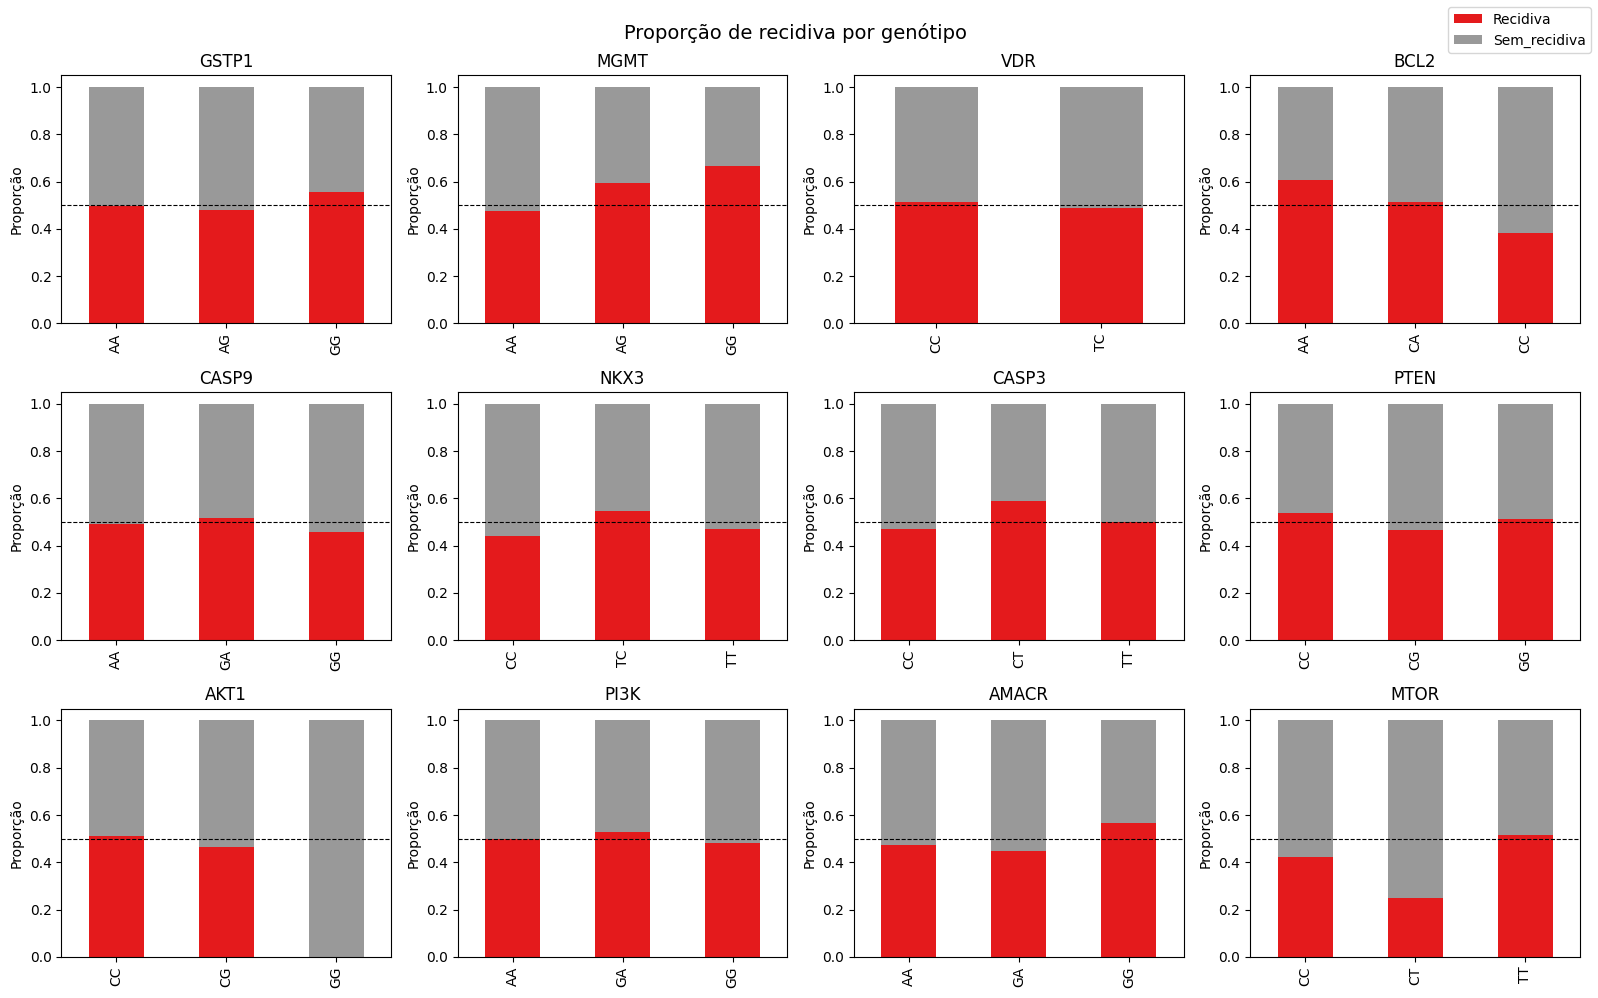

In [ ]:
# Proporção de recidiva por genótipo de cada gene
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, gene in zip(axes.flatten(), lista_genes):
    # Percentual de pacientes com/sem recidiva dentro de cada genótipo
    tabela = pd.crosstab(
        df_followup[gene], df_followup["cancer_recurrence"].map(mapa_classes), normalize="index"
    )
    tabela.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="Set1")
    ax.set_title(gene)
    ax.set_xlabel("")
    ax.set_ylabel("Proporção")
    ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("Proporção de recidiva por genótipo", fontsize=14)
plt.tight_layout()
plt.show()